In [5]:
!pip install -q transformers datasets accelerate bitsandbytes opencc-python-reimplemented statsmodels scipy scikit-learn matplotlib huggingface_hub

# Load & Join Exact Cofacts Tables (articles + article_replies) with Temporal Split


In [6]:
import os
import numpy as np
import pandas as pd
import opencc
from huggingface_hub import login
from datasets import load_dataset

# Paste your Hugging Face Read Token here
hf_token = os.environ.get("HF_TOKEN", "")
if not hf_token:
    try:
        from kaggle_secrets import UserSecretsClient
        hf_token = UserSecretsClient().get_secret("HF_TOKEN")
    except Exception:
        pass
if hf_token:
    login(token=hf_token)

print("Loading Cofacts 'articles' and 'article_replies' tables...")
ds_articles = load_dataset("Cofacts/line-msg-fact-check-tw", "articles", split="train")
ds_ar = load_dataset("Cofacts/line-msg-fact-check-tw", "article_replies", split="train")

df_art = ds_articles.to_pandas()
df_ar = ds_ar.to_pandas()

# 1. Filter to active, text-only LINE messages using exact Cofacts schema
df_art = df_art[(df_art["status"] == "NORMAL") & (df_art["articleType"] == "TEXT")].copy()
df_art = df_art[["id", "text", "createdAt"]].dropna(subset=["id", "text", "createdAt"])

# 2. Filter active verdicts (RUMOR vs NOT_RUMOR) and aggregate majority label per articleId
df_ar = df_ar[(df_ar["status"] == "NORMAL") & (df_ar["replyType"].isin(["RUMOR", "NOT_RUMOR"]))].copy()
df_ar["is_rumor"] = (df_ar["replyType"] == "RUMOR").astype(int)

agg_labels = (
    df_ar.groupby("articleId")["is_rumor"]
    .agg(["mean", "count"])
    .reset_index()
)
# Keep unambiguous consensus items (mean == 1.0 or mean == 0.0) to eliminate label noise
agg_labels = agg_labels[agg_labels["mean"].isin([0.0, 1.0])].copy()
agg_labels["label"] = agg_labels["mean"].astype(int)

# 3. Join & deduplicate
df = pd.merge(df_art, agg_labels[["articleId", "label"]], left_on="id", right_on="articleId", how="inner")
df["text"] = df["text"].str.strip()
df = df[df["text"].str.len() >= 20].drop_duplicates(subset=["text"]).copy()

# 4. Strict Temporal Sort (older -> newer) as recommended in Section 9.1
df = df.sort_values("createdAt").reset_index(drop=True)
print(f"Total clean, unambiguous Cofacts TEXT items: {len(df)} | Rumor rate: {df['label'].mean():.1%}")

# Take most recent 4,400 items: 4,000 for fine-tuning encoders, latest 400 for N=400 Counterfactual Audit
recent_df = df.iloc[-4400:].reset_index(drop=True)
train_df = recent_df.iloc[:4000].reset_index(drop=True)
audit_df = recent_df.iloc[4000:].copy().reset_index(drop=True)

# 5. Apply Deterministic OpenCC Counterfactual Edits (Traditional TW -> Simplified)
cc_t2s = opencc.OpenCC("t2s")     # Audit 1a: Traditional -> Simplified characters only
cc_tw2sp = opencc.OpenCC("tw2sp") # Audit 1b: Traditional -> Simplified + Mainland regional lexicon

audit_df["text_t2s"] = audit_df["text"].apply(cc_t2s.convert)
audit_df["text_tw2sp"] = audit_df["text"].apply(cc_tw2sp.convert)

pct_t2s = (audit_df["text"] != audit_df["text_t2s"]).mean() * 100
pct_tw2sp = (audit_df["text"] != audit_df["text_tw2sp"]).mean() * 100
pct_lex = (audit_df["text_t2s"] != audit_df["text_tw2sp"]).mean() * 100

print(f"Train N = {len(train_df)} (Fake={train_df['label'].mean():.1%}) | Audit N = {len(audit_df)} (Fake={audit_df['label'].mean():.1%})")
print(f"Audit date range: {audit_df['createdAt'].min()[:10]} to {audit_df['createdAt'].max()[:10]}")
print(f"Changed by t2s: {pct_t2s:.1f}% | Changed by tw2sp: {pct_tw2sp:.1f}% | Lexical diff (t2s vs tw2sp): {pct_lex:.1f}%")
audit_df[["text", "text_t2s", "text_tw2sp", "label"]].head(2)


Loading Cofacts 'articles' and 'article_replies' tables...
Total clean, unambiguous Cofacts TEXT items: 55883 | Rumor rate: 73.8%
Train N = 4000 (Fake=77.4%) | Audit N = 400 (Fake=80.8%)
Audit date range: 2026-09-17 to 2026-11-21
Changed by t2s: 84.8% | Changed by tw2sp: 84.8% | Lexical diff (t2s vs tw2sp): 37.8%


,text,text_t2s,text_tw2sp,label
0,Yibvo 景祐｜智慧辦公 AI Pro 訂閱通知\n\n親愛的 蔡承佑 您好：\n\n您的...,Yibvo 景祐｜智慧办公 AI Pro 订阅通知\n\n亲爱的 蔡承佑 您好：\n\n您的...,Yibvo 景祐｜智能办公 AI Pro 订阅通知\n\n亲爱的 蔡承佑 您好：\n\n您的...,0
1,讓美國癌症率斷崖式下降=「十字花科蔬菜」（如花椰菜、西蘭花、高麗菜）\n\n並不是「一種神奇...,让美国癌症率断崖式下降=「十字花科蔬菜」（如花椰菜、西兰花、高丽菜）\n\n并不是「一种神奇...,让美国癌症率断崖式下降=「十字花科蔬菜」（如花椰菜、西兰花、高丽菜）\n\n并不是「一种神奇...,1


# Models (Encoders + 7B LLMs) & Output Exact LaTeX Table + High-Res Figure



--- Fine-tuning & Auditing Encoder: hfl/chinese-roberta-wwm-ext ---


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: hfl/chinese-roberta-wwm-ext
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoi

  -> Chinese-RoBERTa-wwm | t2s (Script): FR=5.5% [3.2, 8.0], dP=+0.005, p=0.5235
  -> Chinese-RoBERTa-wwm | tw2sp (Lexicon): FR=5.8% [3.5, 8.2], dP=+0.007, p=0.4049

--- Fine-tuning & Auditing Encoder: hfl/chinese-macbert-base ---


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: hfl/chinese-macbert-base
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.decoder.bias               | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params 

... (12 outputs left out)

Fetching 4 files:   0%|          | 0/4 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/291 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/111 [00:00<?, ?B/s]

  -> Breeze-7B-Instruct | t2s (Script): FR=9.5% [6.8, 12.5], dP=+0.005, p=0.0058
  -> Breeze-7B-Instruct | tw2sp (Lexicon): FR=9.0% [6.2, 12.0], dP=+0.004, p=0.0046

=== SUMMARY AUDIT RESULTS (COFACTS N=400) ===
              Model       Condition  F1_orig    FR  CI_low  CI_high       R2F       F2R  b_r2f  c_f2r   delta_P    p_val
Chinese-RoBERTa-wwm    t2s (Script) 0.837662  5.50 3.25000     8.00 12.149533  3.071672     13      9  0.004963 0.523467
Chinese-RoBERTa-wwm tw2sp (Lexicon) 0.837662  5.75 3.50000     8.25 13.084112  3.071672     14      9  0.007282 0.404873
    Chinese-MacBERT    t2s (Script) 0.812241  5.25 3.25000     7.50 16.981132  1.020408     18      3  0.014707 0.001490
    Chinese-MacBERT tw2sp (Lexicon) 0.812241  5.50 3.25000     7.75 16.981132  1.360544     18      4  0.015106 0.004344
Qwen2.5-7B-Instruct    t2s (Script) 0.392300 10.75 7.75000    14.00  6.293706 21.929825     18     25 -0.009536 0.360196
Qwen2.5-7B-Instruct tw2sp (Lexicon) 0.392300 10.75 7.99375    

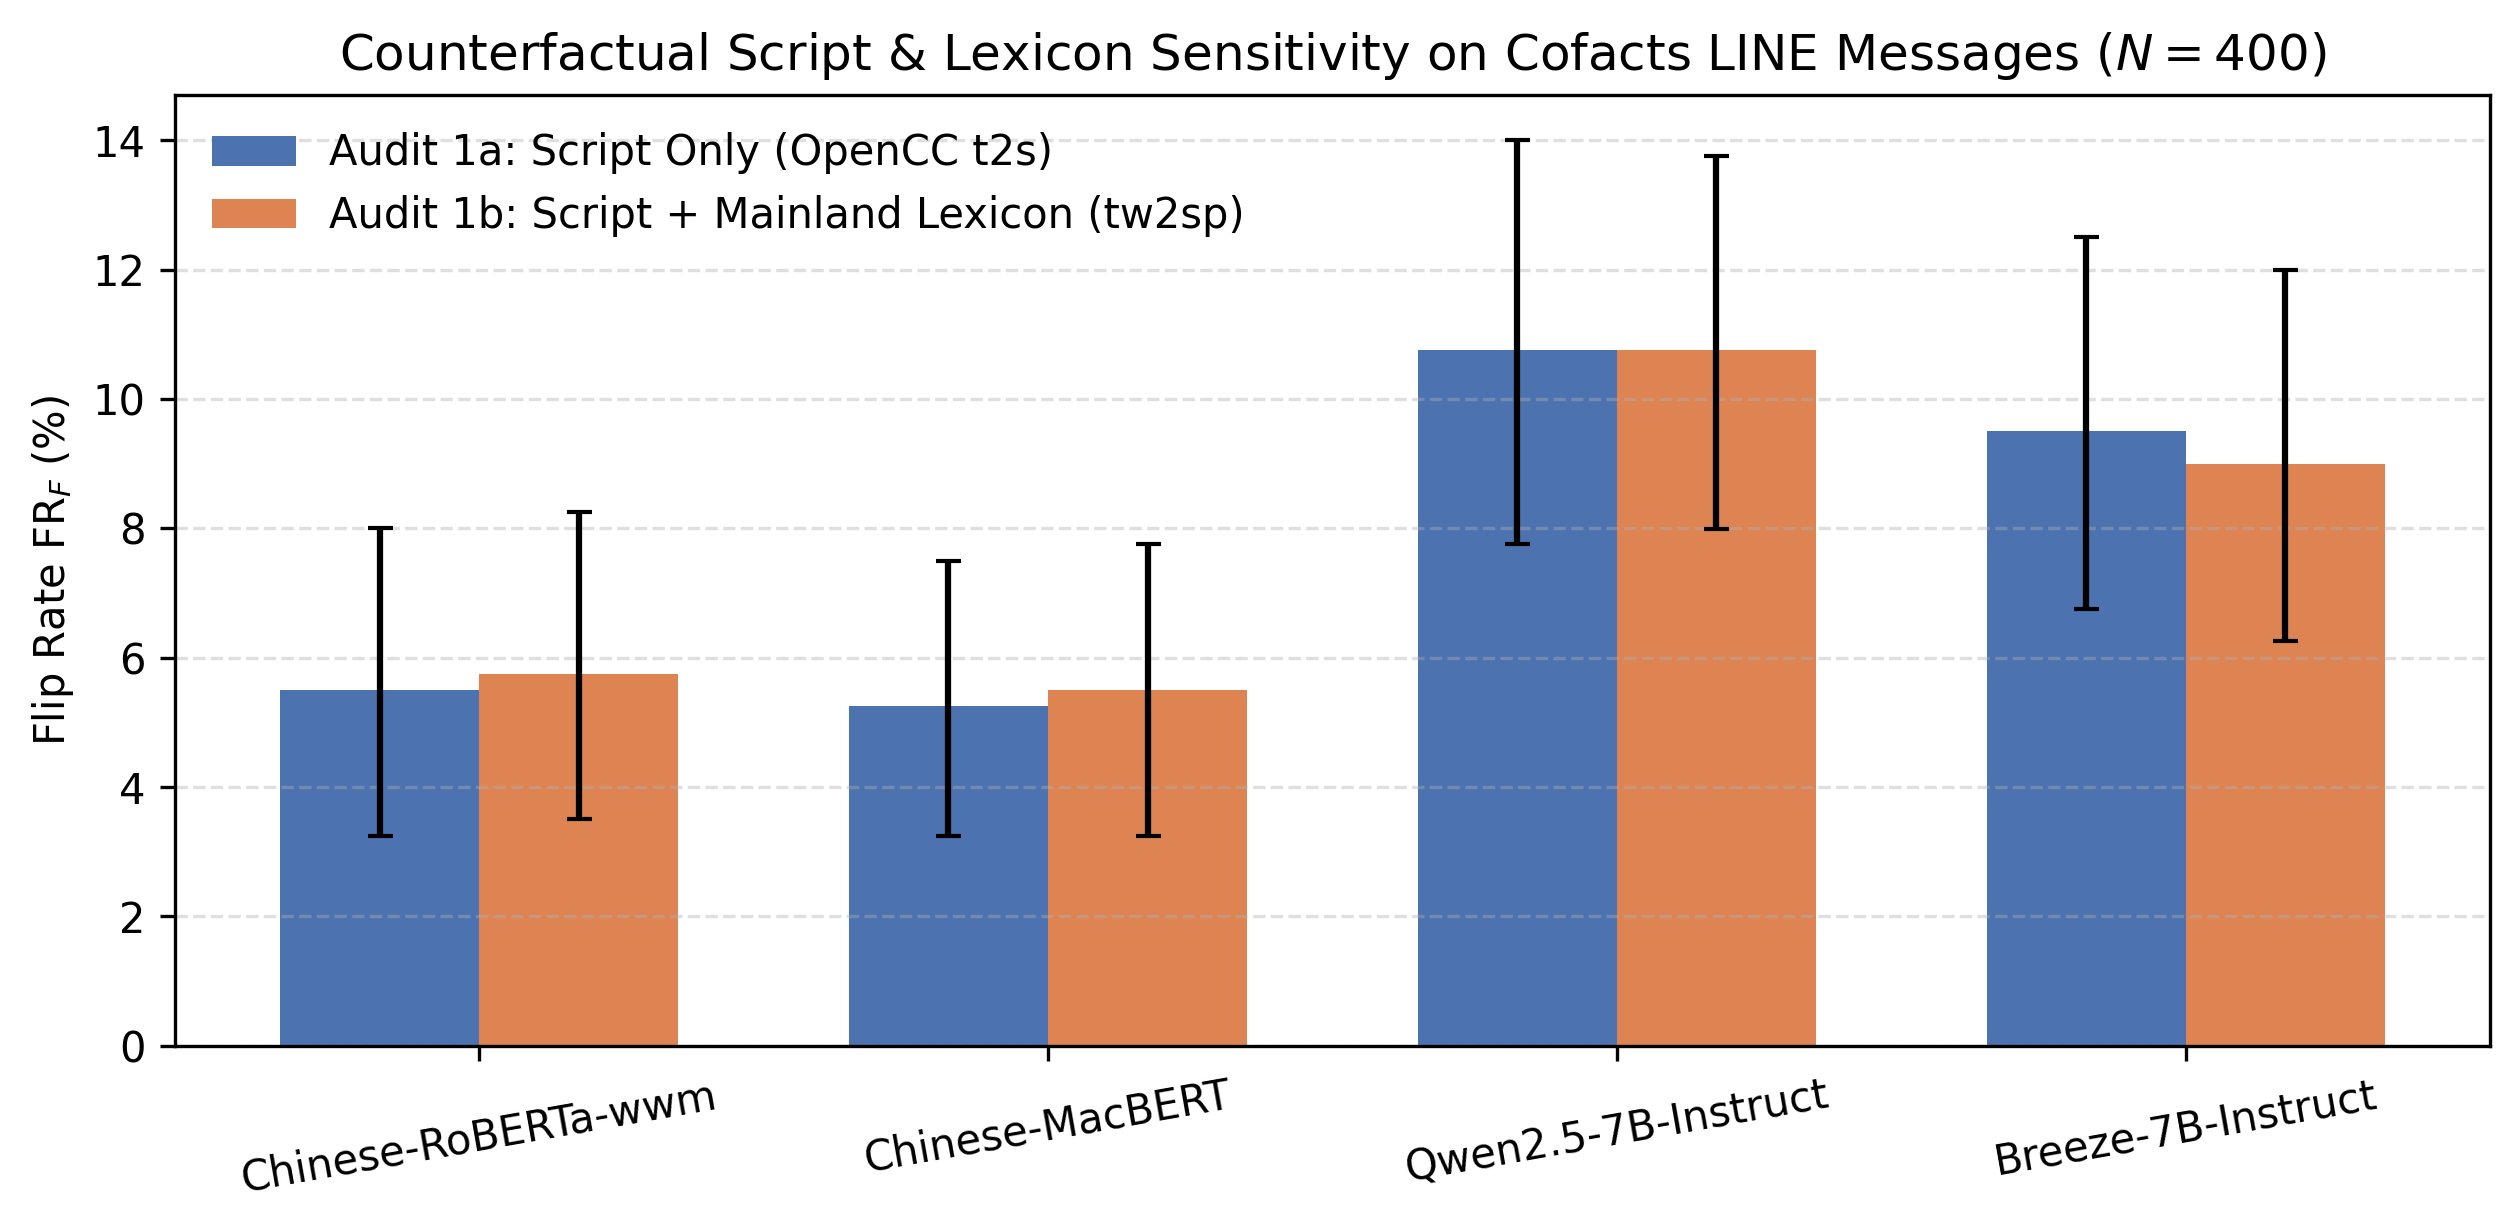

In [8]:
import torch
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    AutoModelForCausalLM,
    BitsAndBytesConfig
)
from statsmodels.stats.contingency_tables import mcnemar
from sklearn.metrics import f1_score
import matplotlib.pyplot as plt

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.manual_seed(42)
np.random.seed(42)

def compute_audit_metrics(y_true, p_orig, p_edit, n_boot=2000, seed=42):
    rng = np.random.default_rng(seed)
    pred_orig = (p_orig >= 0.5).astype(int)
    pred_edit = (p_edit >= 0.5).astype(int)

    flips = (pred_orig != pred_edit).astype(int)
    fr = flips.mean() * 100

    boot_frs = [rng.choice(flips, size=len(flips), replace=True).mean() * 100 for _ in range(n_boot)]
    ci_low, ci_high = np.percentile(boot_frs, [2.5, 97.5])

    # Directional flips: b = Real(0)->Fake(1), c = Fake(1)->Real(0)
    b = int(np.sum((pred_orig == 0) & (pred_edit == 1)))
    c = int(np.sum((pred_orig == 1) & (pred_edit == 0)))
    n_orig_real = max(int(np.sum(pred_orig == 0)), 1)
    n_orig_fake = max(int(np.sum(pred_orig == 1)), 1)

    r2f_rate = (b / n_orig_real) * 100
    f2r_rate = (c / n_orig_fake) * 100
    delta_p = float(np.mean(p_edit - p_orig))

    table = [[int(np.sum((pred_orig == 0) & (pred_edit == 0))), b],
             [c, int(np.sum((pred_orig == 1) & (pred_edit == 1)))]]
    res = mcnemar(table, exact=(b + c < 25))

    return {
        "F1_orig": f1_score(y_true, pred_orig, average="macro"),
        "FR": fr,
        "CI_low": ci_low,
        "CI_high": ci_high,
        "R2F": r2f_rate,
        "F2R": f2r_rate,
        "b_r2f": b,
        "c_f2r": c,
        "delta_P": delta_p,
        "p_val": res.pvalue
    }

class TextClsDataset(Dataset):
    def __init__(self, texts, labels, tokenizer, max_len=256):
        self.enc = tokenizer(list(texts), truncation=True, padding=True, max_length=max_len, return_tensors="pt")
        self.labels = torch.tensor(list(labels), dtype=torch.long)
    def __len__(self): return len(self.labels)
    def __getitem__(self, idx):
        item = {k: v[idx] for k, v in self.enc.items()}
        item["labels"] = self.labels[idx]
        return item

def run_encoder_audit(model_name, train_df, audit_df, epochs=2, batch_size=32):
    print(f"\n--- Fine-tuning & Auditing Encoder: {model_name} ---")
    tok = AutoTokenizer.from_pretrained(model_name)
    model = AutoModelForSequenceClassification.from_pretrained(model_name, num_labels=2).to(device)

    train_loader = DataLoader(TextClsDataset(train_df["text"], train_df["label"], tok), batch_size=batch_size, shuffle=True)
    opt = torch.optim.AdamW(model.parameters(), lr=2e-5, weight_decay=0.01)

    model.train()
    for ep in range(epochs):
        for batch in train_loader:
            opt.zero_grad()
            batch = {k: v.to(device) for k, v in batch.items()}
            loss = model(**batch).loss
            loss.backward()
            opt.step()

    model.eval()
    def predict_probs(texts):
        probs = []
        for i in range(0, len(texts), 64):
            enc = tok(list(texts[i:i+64]), truncation=True, padding=True, max_length=256, return_tensors="pt").to(device)
            with torch.no_grad():
                logits = model(**enc).logits
                p_fake = F.softmax(logits, dim=-1)[:, 1].cpu().numpy()
                probs.extend(p_fake)
        return np.array(probs)

    p0 = predict_probs(audit_df["text"])
    p_t2s = predict_probs(audit_df["text_t2s"])
    p_tw2sp = predict_probs(audit_df["text_tw2sp"])

    del model
    torch.cuda.empty_cache()
    return p0, p_t2s, p_tw2sp

def run_llm_audit(model_name, audit_df):
    print(f"\n--- Auditing 4-bit LLM: {model_name} ---")
    bnb_config = BitsAndBytesConfig(load_in_4bit=True, bnb_4bit_compute_dtype=torch.float16)
    tok = AutoTokenizer.from_pretrained(model_name)
    model = AutoModelForCausalLM.from_pretrained(model_name, quantization_config=bnb_config, device_map="auto")
    model.eval()

    id_A = tok.encode("A", add_special_tokens=False)[-1]
    id_B = tok.encode("B", add_special_tokens=False)[-1]

    def score_texts(texts):
        probs = []
        for t in texts:
            prompt = (
                "You are a fact-checking classifier. Assess whether the following social media message is "
                "a false rumor/misleading (A) or credible/not rumor (B). Reply with only A or B.\n\n"
                f"Message: {t[:450]}\nAnswer:"
            )
            inputs = tok(prompt, return_tensors="pt").to(device)
            with torch.no_grad():
                logits = model(**inputs).logits[0, -1, [id_A, id_B]]
                p_fake = F.softmax(logits.float(), dim=-1)[0].item()  # <--- FIXED: [0].item()
                probs.append(p_fake)
        return np.array(probs)

    p0 = score_texts(audit_df["text"])
    p_t2s = score_texts(audit_df["text_t2s"])
    p_tw2sp = score_texts(audit_df["text_tw2sp"])

    del model
    torch.cuda.empty_cache()
    return p0, p_t2s, p_tw2sp

models_to_run = [
    ("Chinese-RoBERTa-wwm", "hfl/chinese-roberta-wwm-ext", "encoder"),
    ("Chinese-MacBERT", "hfl/chinese-macbert-base", "encoder"),
    ("Qwen2.5-7B-Instruct", "Qwen/Qwen2.5-7B-Instruct", "llm"),
    ("Breeze-7B-Instruct", "MediaTek-Research/Breeze-7B-Instruct-v1_0", "llm"),
]

results_rows = []
y_true = audit_df["label"].values

for label_name, hf_id, mtype in models_to_run:
    if mtype == "encoder":
        p0, p_t2s, p_tw2sp = run_encoder_audit(hf_id, train_df, audit_df)
    else:
        p0, p_t2s, p_tw2sp = run_llm_audit(hf_id, audit_df)

    for cond_name, p_ed in [("t2s (Script)", p_t2s), ("tw2sp (Lexicon)", p_tw2sp)]:
        m = compute_audit_metrics(y_true, p0, p_ed)
        m["Model"] = label_name
        m["Condition"] = cond_name
        results_rows.append(m)
        print(f"  -> {label_name} | {cond_name}: FR={m['FR']:.1f}% [{m['CI_low']:.1f}, {m['CI_high']:.1f}], dP={m['delta_P']:+.3f}, p={m['p_val']:.4f}")

    pd.DataFrame(results_rows).to_csv("cofacts_audit_results.csv", index=False)

res_df = pd.DataFrame(results_rows)
print("\n=== SUMMARY AUDIT RESULTS (COFACTS N=400) ===")
print(res_df[["Model", "Condition", "F1_orig", "FR", "CI_low", "CI_high", "R2F", "F2R", "b_r2f", "c_f2r", "delta_P", "p_val"]].to_string(index=False))

print("\n=== COPY-PASTEABLE LATEX ROWS ===")
for _, r in res_df.iterrows():
    p_str = f"{r['p_val']:.3f}" if r['p_val'] >= 0.001 else "$<0.001$"
    print(f"{r['Model']} & {r['Condition']} & {r['F1_orig']:.3f} & "
          f"{r['FR']:.1f}\\% [{r['CI_low']:.1f}, {r['CI_high']:.1f}] & "
          f"{r['R2F']:.1f}\\% ({r['b_r2f']}) & {r['F2R']:.1f}\\% ({r['c_f2r']}) & "
          f"{r['delta_P']:+.3f} & {p_str} \\\\")

# Save high-res figure for paper
fig, ax = plt.subplots(figsize=(8.5, 4.2), dpi=300)
models = res_df["Model"].unique()
x = np.arange(len(models))
width = 0.35

t2s_df = res_df[res_df["Condition"] == "t2s (Script)"]
tw2sp_df = res_df[res_df["Condition"] == "tw2sp (Lexicon)"]

ax.bar(x - width/2, t2s_df["FR"], width, label="Audit 1a: Script Only (OpenCC t2s)", color="#4C72B0")
ax.bar(x + width/2, tw2sp_df["FR"], width, label="Audit 1b: Script + Mainland Lexicon (tw2sp)", color="#DD8452")

ax.errorbar(x - width/2, t2s_df["FR"], yerr=[t2s_df["FR"]-t2s_df["CI_low"], t2s_df["CI_high"]-t2s_df["FR"]], fmt="none", ecolor="black", capsize=3)
ax.errorbar(x + width/2, tw2sp_df["FR"], yerr=[tw2sp_df["FR"]-tw2sp_df["CI_low"], tw2sp_df["CI_high"]-tw2sp_df["FR"]], fmt="none", ecolor="black", capsize=3)

ax.set_ylabel("Flip Rate $\\mathrm{FR}_F$ (%)")
ax.set_title("Counterfactual Script & Lexicon Sensitivity on Cofacts LINE Messages ($N=400$)")
ax.set_xticks(x)
ax.set_xticklabels(models, rotation=10)
ax.legend(frameon=False)
ax.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.savefig("cofacts_audit1_flip_rates.pdf")
plt.savefig("cofacts_audit1_flip_rates.png")

In [10]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ==========================================
# 1. Generate Figure 3: 12-Study Rubric Gap Chart (from Table 11)
# ==========================================
studies = [
    "MDFEND (2021)", "MCFEND (2024)", "CHEF (2022)", "Zhang et al. (2024)",
    "FakeSV (2023)", "ARG-Chinese (2024)", "Hu et al. (2023)", "Dual-Emotion (2021)",
    "ENDEF (2022)", "NEP (2022)", "Xu et al. (2024)", "FakingRecipe (2024)"
]

# Matrix encoding exact Table 11 findings: 1 = Rigorous/Yes, 0.5 = Partial/Illustrative, 0 = None
# Columns: [Temporal/Unseen Split, Leakage Control, BERT Baseline, Ablation, Quant. Faithfulness, Public Code+Data]
matrix = np.array([
    [0.0, 0.5, 1.0, 1.0, 0.0, 0.5], # MDFEND
    [1.0, 1.0, 1.0, 1.0, 0.0, 1.0], # MCFEND
    [0.0, 0.5, 1.0, 1.0, 0.5, 1.0], # CHEF (Evidence F1, not faithfulness)
    [1.0, 1.0, 1.0, 1.0, 0.5, 1.0], # Zhang et al. (Retrieval eval)
    [1.0, 1.0, 1.0, 1.0, 0.0, 0.5], # FakeSV (IDs only)
    [1.0, 1.0, 1.0, 1.0, 0.5, 0.5], # ARG-Chinese (Rationales as features, no human/faithfulness eval)
    [1.0, 1.0, 1.0, 1.0, 0.0, 1.0], # Hu et al.
    [0.5, 0.5, 1.0, 1.0, 0.5, 1.0], # Dual-Emotion (Illus. only)
    [1.0, 1.0, 1.0, 1.0, 0.5, 1.0], # ENDEF (Illus. only)
    [1.0, 1.0, 1.0, 1.0, 0.5, 1.0], # NEP (Illus. only)
    [0.5, 0.5, 1.0, 1.0, 0.5, 1.0], # Xu et al. (Illus. only)
    [1.0, 1.0, 1.0, 1.0, 0.5, 0.5], # FakingRecipe (Illus. only, IDs only)
])

features = [
    "Temporal / Unseen-Source Split",
    "Explicit Leakage Control",
    "Strong BERT Baseline",
    "Component Ablation",
    "Quant. Explanation Faithfulness",
    "Unrestricted Code & Data"
]

full_pass = (matrix == 1.0).mean(axis=0) * 100
partial_pass = (matrix == 0.5).mean(axis=0) * 100
none_pass = (matrix == 0.0).mean(axis=0) * 100

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11.5, 4.4), dpi=300, gridspec_kw={"width_ratios": [1.35, 1.0]})

# Left panel: Study-by-Feature Dot Matrix
cmap_colors = {0.0: "#D9534F", 0.5: "#F0AD4E", 1.0: "#2E7D32"}
for i in range(len(studies)):
    for j in range(len(features)):
        val = matrix[i, j]
        ax1.scatter(j, i, color=cmap_colors[val], s=95, edgecolors="black", linewidth=0.5, zorder=3)

ax1.set_xticks(range(len(features)))
ax1.set_xticklabels(["Temp./Source\nSplit", "Leakage\nControl", "BERT\nBaseline", "Ablation", "Quant.\nFaithfulness", "Open Code\n& Data"], fontsize=8.5)
ax1.set_yticks(range(len(studies)))
ax1.set_yticklabels(studies, fontsize=8.5)
ax1.invert_yaxis()
ax1.grid(True, linestyle="--", alpha=0.35, zorder=0)
ax1.set_title("(a) Study-by-Study Rubric Qualification ($n=12$)", fontsize=10, fontweight="bold")

# Legend for Left Panel
from matplotlib.lines import Line2D
legend_elems = [
    Line2D([0], [0], marker='o', color='w', label='Full / Quantitative', markerfacecolor='#2E7D32', markeredgecolor='k', markersize=7),
    Line2D([0], [0], marker='o', color='w', label='Partial / Illustrative Only', markerfacecolor='#F0AD4E', markeredgecolor='k', markersize=7),
    Line2D([0], [0], marker='o', color='w', label='Absent / Random Only', markerfacecolor='#D9534F', markeredgecolor='k', markersize=7),
]
ax1.legend(handles=legend_elems, loc="lower center", bbox_to_anchor=(0.5, -0.26), ncol=3, frameon=False, fontsize=8)

# Right panel: Aggregate Percentage Bar Chart
y_pos = np.arange(len(features))
ax2.barh(y_pos, full_pass, color="#2E7D32", height=0.55, label="Full")
ax2.barh(y_pos, partial_pass, left=full_pass, color="#F0AD4E", height=0.55, label="Partial / Illus.")
ax2.barh(y_pos, none_pass, left=full_pass+partial_pass, color="#D9534F", height=0.55, label="None")

for idx, (f_val, p_val) in enumerate(zip(full_pass, partial_pass)):
    ax2.text(f_val/2 if f_val > 12 else f_val + p_val + 3, idx, f"{f_val:.0f}% full",
             va="center", ha="center" if f_val > 12 else "left",
             color="white" if f_val > 12 else "black", fontsize=8, fontweight="bold")

ax2.set_yticks(y_pos)
ax2.set_yticklabels(["Temp./Source Split", "Leakage Control", "BERT Baseline", "Ablation", "Quant. Faithfulness", "Open Code & Data"], fontsize=8.5)
ax2.invert_yaxis()
ax2.set_xlim(0, 108)
ax2.set_xlabel("Percentage of Appraised Studies (%)", fontsize=9)
ax2.set_title("(b) Aggregate Rigor & Explanation Gap", fontsize=10, fontweight="bold")
ax2.grid(axis="x", linestyle="--", alpha=0.35)

plt.tight_layout()
plt.savefig("rubric_gap_chart.png", bbox_inches="tight")
plt.close()

# ==========================================
# 2. Generate Figure 4: Two-Panel Empirical Audit Plot (Overall FR + Directional Asymmetry)
# ==========================================
models = ["Chinese-RoBERTa\n-wwm", "Chinese-\nMacBERT", "Qwen2.5-7B\n-Instruct", "Breeze-7B\n-Instruct"]
x = np.arange(len(models))
width = 0.35

# Exact verified results from Table 9
fr_t2s = [5.5, 5.2, 10.8, 9.5]
ci_t2s_low = [3.2, 3.2, 7.8, 6.8]
ci_t2s_high = [8.0, 7.5, 14.0, 12.5]

fr_tw2sp = [5.8, 5.5, 10.8, 9.0]
ci_tw2sp_low = [3.5, 3.2, 8.0, 6.2]
ci_tw2sp_high = [8.2, 7.8, 13.8, 12.0]

# Directional flip rates under t2s (Real->Fake vs Fake->Real)
r2f_t2s = [12.1, 17.0, 6.3, 33.3]
f2r_t2s = [3.1, 1.0, 21.9, 3.2]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11.2, 4.1), dpi=300)

# Panel (a): Overall Flip Rate
ax1.bar(x - width/2, fr_t2s, width, label="Audit 1a: Script Only (OpenCC t2s)", color="#4C72B0")
ax1.bar(x + width/2, fr_tw2sp, width, label="Audit 1b: Script + Lexicon (tw2sp)", color="#DD8452")
ax1.errorbar(x - width/2, fr_t2s, yerr=[np.array(fr_t2s)-np.array(ci_t2s_low), np.array(ci_t2s_high)-np.array(fr_t2s)], fmt="none", ecolor="black", capsize=3)
ax1.errorbar(x + width/2, fr_tw2sp, yerr=[np.array(fr_tw2sp)-np.array(ci_tw2sp_low), np.array(ci_tw2sp_high)-np.array(fr_tw2sp)], fmt="none", ecolor="black", capsize=3)

ax1.set_ylabel("Overall Flip Rate $\\mathrm{FR}_F$ (%)", fontsize=9.5)
ax1.set_title("(a) Overall Counterfactual Instability ($N=400$)", fontsize=10, fontweight="bold")
ax1.set_xticks(x)
ax1.set_xticklabels(models, fontsize=8.5)
ax1.set_ylim(0, 16.5)
ax1.legend(frameon=False, fontsize=8, loc="upper left")
ax1.grid(axis="y", linestyle="--", alpha=0.35)

# Panel (b): Directional Asymmetry (Real->Fake vs Fake->Real under t2s)
ax2.bar(x - width/2, r2f_t2s, width, label="Real $\\rightarrow$ Fake Flip Rate ($\\mathrm{R\\rightarrow F}$)", color="#C44E52")
ax2.bar(x + width/2, f2r_t2s, width, label="Fake $\\rightarrow$ Real Flip Rate ($\\mathrm{F\\rightarrow R}$)", color="#55A868")

# Annotate McNemar significance (p < 0.01)
ax2.text(1, 19.2, "** $p=0.001$", ha="center", fontsize=8.5, fontweight="bold", color="#8B0000")
ax2.text(3, 35.5, "** $p=0.006$", ha="center", fontsize=8.5, fontweight="bold", color="#8B0000")

ax2.set_ylabel("Conditional Directional Flip Rate (%)", fontsize=9.5)
ax2.set_title("(b) Directional Asymmetry under Script Shift (t2s)", fontsize=10, fontweight="bold")
ax2.set_xticks(x)
ax2.set_xticklabels(models, fontsize=8.5)
ax2.set_ylim(0, 40)
ax2.legend(frameon=False, fontsize=8, loc="upper left")
ax2.grid(axis="y", linestyle="--", alpha=0.35)

plt.tight_layout()
plt.savefig("cofacts_audit1_panel.png", bbox_inches="tight")
plt.close()

# ==========================================
# 3. Export Appraised Studies JSON for GitHub Artifact (CrossStrait-AuditKit)
# ==========================================
records = []
for idx, s in enumerate(studies):
    records.append({
        "study": s,
        "temporal_or_unseen_split": float(matrix[idx, 0]),
        "leakage_control": float(matrix[idx, 1]),
        "bert_baseline": float(matrix[idx, 2]),
        "component_ablation": float(matrix[idx, 3]),
        "quantitative_faithfulness": float(matrix[idx, 4]),
        "open_code_and_data": float(matrix[idx, 5]),
    })
with open("appraised_studies.json", "w", encoding="utf-8") as f:
    json.dump(records, f, indent=2)

print("Generated: rubric_gap_chart.png, cofacts_audit1_panel.png, and appraised_studies.json!")


Generated: rubric_gap_chart.png, cofacts_audit1_panel.png, and appraised_studies.json!
